# 5 — Onde o modelo erra ao converter ASTs em skeletons

Analisamos o Transformer que terminou o treinamento no corpus de cinco milhões de ASTs, usando o checkpoint da época 10. O objetivo é localizar dificuldades da transformação simbólica: ordenar erros por quantidade de operações, inspecionar exemplos e verificar padrões no teste inteiro. Cada skeleton ocorre uma única vez no teste e está ausente do treino e da validação. As métricas tratam da recuperação do skeleton; os coeficientes das fórmulas de entrada são informações recebidas pelo encoder.

O protocolo reserva cerca de 10% do teste, por hash do skeleton, para descoberta de padrões e os outros 90% para confirmação. As hipóteses foram escolhidas após examinar apenas 9.223 exemplos de descoberta nos primeiros 24 arquivos. O relatório também apresenta os totais dos 850.465 casos. Um experimento adicional troca os filhos das operações comutativas sem mudar a função e observa a resposta do modelo. Essas associações descrevem o comportamento deste checkpoint; identificar causalmente uma deficiência da arquitetura exigiria novos treinamentos controlados.


In [1]:
from pathlib import Path
from hashlib import sha256
import json, platform, sys, re
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/tsfmxai').exists())
sys.path.insert(0,str(ROOT/'src'))
from tsfmxai.evaluation.canonical_errors import (
    grouped_errors, hypothesis_table, HYPOTHESES, commutative_probe, load_analysis_model,
    diagnostic_example, swap_children, classify_prediction, structural_features,
)
from tsfmxai.symbolic_regression.canonical_models import collate_canonical
RUN = ROOT/'outputs/canonicalization/ast_5m_unique_eval_20261030'
AUDIT = ROOT/'outputs/canonicalization/error_analysis_20261031'
CONFIG = ROOT/'configs/canonicalization_5m_ast_parquet_unique_eval.json'
CHECKPOINT = RUN/'checkpoints/transformer_skeleton/best.pt'
SELECTED_HYPOTHESES = ['at_least_25_output_tokens','product_of_two_sums',
                       'at_least_two_merged_occurrences','power_in_target',
                       'degree_four','deep_tree']
SEED = 20261103
torch.set_num_threads(4)
status=json.loads((AUDIT/'status.json').read_text(encoding='utf8'))
assert status['state']=='completed', 'Execute scripts/analyze_canonical_errors.py first.'
manifest=json.loads((AUDIT/'manifest.json').read_text(encoding='utf8'))
assert sha256(CHECKPOINT.read_bytes()).hexdigest()==manifest['checkpoint_sha256']
data=pd.concat([pq.read_table(p).to_pandas() for p in sorted(AUDIT.glob('part-*.parquet'))],ignore_index=True)
assert data.sample_index.is_unique and data.skeleton_hash.is_unique
discovery=data[data.analysis_partition=='discovery'].copy()
confirmation=data[data.analysis_partition=='confirmation'].copy()
selection_slice=discovery[discovery.sample_index<24*20000]
print('Teste completo:',len(data),'| descoberta:',len(discovery),'| confirmação:',len(confirmation))
print('Casos usados para escolher hipóteses:',len(selection_slice))
pd.set_option('display.max_colwidth',None)
pd.set_option('display.max_rows',80)


Teste completo: 850465 | descoberta: 85265 | confirmação: 765200
Casos usados para escolher hipóteses: 9223


**O que esta célula faz:** Carrega os resultados de inferência, confere o checkpoint e mantém separados os casos usados para explorar e confirmar os padrões.

## 1. Conferência global e ordem por número de operações

Exemplos de teste                                    850465.000000
Erros completos                                       14175.000000
Skeleton exato (%)                                       98.333265
Saída válida (%)                                         99.383866
Acerto anteriormente registrado (%)                      98.333265
Erros após apenas ordenar/reunir termos repetidos     11106.000000
dtype: float64

,operator_count,examples,errors,error_pct,error_low_pct,error_high_pct
0,4,110,22,20.0000,13.5951,28.4295
1,5,9855,95,0.9640,0.7893,1.1769
2,6,840500,14058,1.6726,1.6454,1.7002


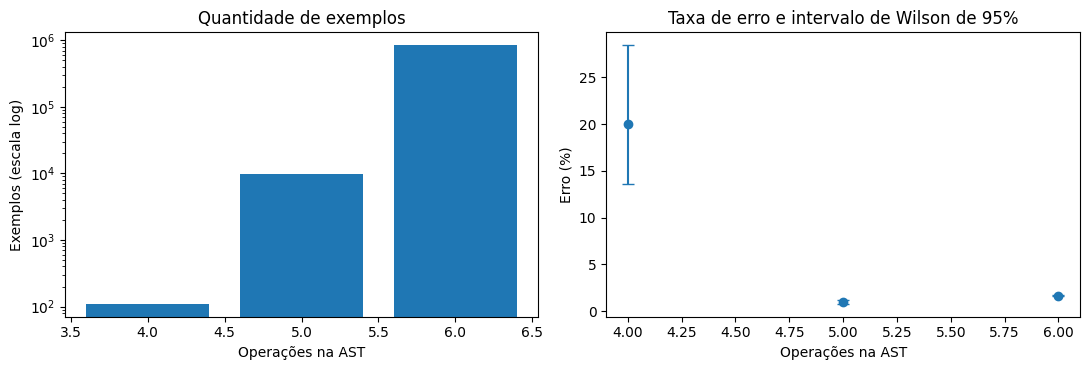

In [2]:
recorded=json.loads((RUN/'status.json').read_text(encoding='utf8'))['results']['transformer_skeleton']
global_metrics={
    'Exemplos de teste':len(data),'Erros completos':int((~data.exact).sum()),
    'Skeleton exato (%)':100*data.exact.mean(),'Saída válida (%)':100*data.valid.mean(),
    'Acerto anteriormente registrado (%)':100*recorded['skeleton_exact'],
    'Erros após apenas ordenar/reunir termos repetidos':int((~data.support_correct_after_sorting).sum()),
}
display(pd.Series(global_metrics))
operator_table=grouped_errors(data,'operator_count')
display(operator_table.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
axes[0].bar(operator_table.operator_count,operator_table.examples)
axes[0].set(title='Quantidade de exemplos',xlabel='Operações na AST',ylabel='Exemplos (escala log)',yscale='log')
axes[1].errorbar(operator_table.operator_count,operator_table.error_pct,
                yerr=[operator_table.error_pct-operator_table.error_low_pct,
                      operator_table.error_high_pct-operator_table.error_pct],fmt='o',capsize=4)
axes[1].set(title='Taxa de erro e intervalo de Wilson de 95%',xlabel='Operações na AST',ylabel='Erro (%)')
fig.tight_layout();plt.show()


**O que esta célula faz:** Reproduz a métrica global e mostra a distribuição por operações com denominadores. Grupos muito pequenos têm incerteza grande.

O sorteador favorece as classes com mais árvores possíveis. Por isso, esta avaliação tem uma concentração muito grande em seis operações. Uma AST com seis operações pode gerar poucos termos ou uma expressão longa depois das distributivas; o número de operações sozinho resume apenas uma parte da dificuldade. O intervalo de Wilson representa a incerteza da taxa dentro de cada grupo, sob uma interpretação binomial; a amostragem condicionada a skeletons distintos também deve ser considerada ao generalizar esses números.

## 2. Trechos da tabela de erros, em complexidade crescente

In [3]:
def short_formula(text):
    text=re.sub(r'x_0\(t-(\d+)\)',r'x_\1',str(text))
    return re.sub(r's_0\[t-(\d+)\]',r'x_\1',text)

def case_table(frame):
    columns=['sample_index','operator_count','target_terms','degree','input_formula',
             'target_formula','predicted_formula','error_category','missing_formula','extra_formula']
    result=frame[columns].copy()
    for column in ('input_formula','target_formula','predicted_formula','missing_formula','extra_formula'):
        result[column]=result[column].map(short_formula)
    return result.rename(columns={'operator_count':'Operações','target_terms':'Termos no alvo',
        'degree':'Grau','input_formula':'Fórmula da AST','target_formula':'Skeleton correto',
        'predicted_formula':'Saída prevista','error_category':'Tipo de erro',
        'missing_formula':'Termos ausentes','extra_formula':'Termos adicionais'})

errors_discovery=discovery[~discovery.exact].sort_values(['operator_count','target_terms','target_tokens','sample_index'])
ordered_errors=data[~data.exact].sort_values(['operator_count','target_terms','target_tokens','depth','sample_index'])
ordered_errors.to_parquet(AUDIT/'errors_ordered.parquet',index=False)
case_table(ordered_errors).to_csv(AUDIT/'errors_ordered.csv',index=False,encoding='utf-8-sig')
windows=[]
for operations,group in errors_discovery.groupby('operator_count'):
    for description,part in [('menor saída',group.head(2)),
                              ('saída intermediária',group.iloc[len(group)//2:len(group)//2+2]),
                              ('maior saída',group.tail(2))]:
        part=part.copy();part['motivation']=f'{operations} operações — {description}'
        windows.append(part)
examples=pd.concat(windows).drop_duplicates('sample_index').sort_values(['operator_count','target_terms','target_tokens'])
cases=case_table(examples)
cases.insert(1,'Motivação',examples.motivation.values)
display(cases.style.set_properties(**{'white-space':'normal','max-width':'420px','text-align':'left'}))
print('Notação: x_k significa x_0(t-k). A constante 1 no skeleton indica a presença de um termo constante; seu valor não é previsto por este modelo.')


,sample_index,Motivação,Operações,Termos no alvo,Grau,Fórmula da AST,Skeleton correto,Saída prevista,Tipo de erro,Termos ausentes,Termos adicionais
9994,49894,4 operações — menor saída,4,3,2,((x_9 + (x_3 * x_5)) + (x_11 * x_10)),x_9 + x_3 * x_5 + x_10 * x_11,x_9 + x_3 * x_5 + x_10 * x_11 + x_10 * x_11,ordering_or_duplicate_only,,
671198,3864966,5 operações — menor saída,5,2,2,((0.772674 + (x_7 * (x_9 + x_9))) + (x_9 * x_7)),1 + x_7 * x_9,1 + x_7 * x_9 + x_7 * x_9,ordering_or_duplicate_only,,
133679,705627,5 operações — menor saída,5,3,3,((((x_7 * x_4) + (0.507304 + x_4)) * x_5) + x_5),x_5 + x_4 * x_5 + x_4 * x_5 * x_7,x_5 + x_5 + x_4 * x_5 + x_4 * x_5 * x_7,ordering_or_duplicate_only,,
234500,1261829,5 operações — saída intermediária,5,4,3,((x_10 + x_9) * ((x_5 + x_4) * (x_3 + x_3))),x_3 * x_4 * x_9 + x_3 * x_4 * x_10 + x_3 * x_5 * x_9 + x_3 * x_5 * x_10,x_3 * x_4 * x_9 + x_3 * x_4 * x_10 + x_3 * x_5 * x_9 + x_3 * x_5 * x_10 + x_3 * x_5 * x_9 + x_3 * x_5 * x_10,ordering_or_duplicate_only,,
432613,2407275,5 operações — saída intermediária,5,4,3,(x_9 * (x_9 * (x_8 + (x_1 + (x_11 + x_2))))),x_1 * x_9 * x_9 + x_2 * x_9 * x_9 + x_8 * x_9 * x_9 + x_9 * x_9 * x_11,x_1 * x_9 * x_9 + x_2 * x_9 * x_9 + x_8 * x_9 * x_9 + x_9 * x_9 * x_9 + x_9 * x_9 * x_11,extra_terms_only,,x_9 * x_9 * x_9
733653,4257042,5 operações — maior saída,5,4,4,((x_1 + x_2) * ((x_11 + x_12) * (x_2 * x_10))),x_1 * x_2 * x_10 * x_11 + x_1 * x_2 * x_10 * x_12 + x_2 * x_2 * x_10 * x_11 + x_2 * x_2 * x_10 * x_12,x_1 * x_2 * x_2 * x_10 + x_1 * x_2 * x_10 * x_11 + x_1 * x_2 * x_10 * x_12 + x_2 * x_2 * x_10 * x_12,missing_and_extra_terms,x_2 * x_2 * x_10 * x_11,x_1 * x_2 * x_2 * x_10
330736,1811548,5 operações — maior saída,5,6,3,((x_6 + (x_5 + x_10)) * ((x_8 + x_11) * x_8)),x_5 * x_8 * x_8 + x_5 * x_8 * x_11 + x_6 * x_8 * x_8 + x_6 * x_8 * x_11 + x_8 * x_8 * x_10 + x_8 * x_10 * x_11,x_5 * x_8 * x_8 + x_5 * x_8 * x_11 + x_6 * x_8 * x_8 + x_6 * x_8 * x_11 + x_8 * x_8 * x_8 + x_8 * x_8 * x_10 + x_8 * x_8 * x_11 + x_8 * x_10 * x_11,extra_terms_only,,x_8 * x_8 * x_8 + x_8 * x_8 * x_11
661669,3805079,6 operações — menor saída,6,2,3,((x_3 * (x_2 * x_2)) + (((0.82631 * 0.787998) * 0.173281) * -0.608035)),1 + x_2 * x_2 * x_3,1 + x_2 + x_2 * x_2 * x_3,extra_terms_only,,x_2
53230,273137,6 operações — menor saída,6,2,3,(x_7 + (((0.0896896 * (x_7 * x_4)) + (x_4 * x_7)) * x_3)),x_7 + x_3 * x_4 * x_7,x_7 + x_3 * x_4 * x_7 + x_3 * x_4 * x_7,ordering_or_duplicate_only,,
842227,4947084,6 operações — saída intermediária,6,6,3,((x_6 + (x_9 + x_5)) * (-0.732674 + ((x_4 * x_7) + 0.83024))),x_5 + x_6 + x_9 + x_4 * x_5 * x_7 + x_4 * x_6 * x_7 + x_4 * x_7 * x_9,1 + x_5 + x_6 + x_9 + x_4 * x_5 * x_7 + x_4 * x_6 * x_7 + x_4 * x_7 * x_9,extra_constant_only,,1


Notação: x_k significa x_0(t-k). A constante 1 no skeleton indica a presença de um termo constante; seu valor não é previsto por este modelo.


**O que esta célula faz:** Seleciona janelas de erros na descoberta, ordenadas pelo número de operações e pelo tamanho do alvo, e explica por que cada exemplo foi incluído.

A coluna de fórmula prevista mostra apenas os termos completos que o parser conseguiu ler. Nos casos `incomplete_syntax`, pode haver um fator final sem fechamento; nesse caso mostramos também os tokens abaixo. Um fator repetido dentro de um termo é preservado: (x_1x_1) é diferente de (x_1).

In [4]:
model,codec,config,checkpoint_epoch=load_analysis_model(CONFIG,CHECKPOINT)
syntax=errors_discovery[errors_discovery.error_category=='incomplete_syntax'].head(3)
display(pd.DataFrame([{'sample_index':r.sample_index,'alvo':codec.target_text(list(r.target_ids)),
                       'previsto':codec.target_text(list(r.prediction_ids))}
                      for r in syntax.itertuples()]))


,sample_index,alvo,previsto
0,25887,"BOS LAG(0, 5) END_TERM LAG(0, 1) LAG(0, 1) LAG(0, 1) END_TERM LAG(0, 1) LAG(0, 1) LAG(0, 4) END_TERM EOS","LAG(0, 5) END_TERM LAG(0, 1) LAG(0, 1) LAG(0, 1) END_TERM LAG(0, 1) LAG(0, 1) LAG(0, 4) END_TERM LAG(0, 1) LAG(0, 1) EOS"
1,129264,"BOS LAG(0, 1) LAG(0, 6) END_TERM LAG(0, 1) LAG(0, 7) END_TERM LAG(0, 1) LAG(0, 11) END_TERM LAG(0, 2) LAG(0, 6) END_TERM LAG(0, 2) LAG(0, 7) END_TERM LAG(0, 2) LAG(0, 11) END_TERM LAG(0, 6) LAG(0, 6) END_TERM LAG(0, 6) LAG(0, 7) END_TERM LAG(0, 6) LAG(0, 11) END_TERM EOS","LAG(0, 1) LAG(0, 6) END_TERM LAG(0, 1) LAG(0, 7) END_TERM LAG(0, 1) LAG(0, 11) END_TERM LAG(0, 2) LAG(0, 6) END_TERM LAG(0, 2) LAG(0, 7) END_TERM LAG(0, 2) LAG(0, 11) END_TERM LAG(0, 6) LAG(0, 6) END_TERM LAG(0, 6) LAG(0, 7) END_TERM LAG(0, 6) LAG(0, 11) END_TERM LAG(0, 7) EOS"
2,4660600,"BOS LAG(0, 1) LAG(0, 2) LAG(0, 3) END_TERM LAG(0, 1) LAG(0, 2) LAG(0, 7) END_TERM LAG(0, 1) LAG(0, 3) LAG(0, 8) END_TERM LAG(0, 1) LAG(0, 3) LAG(0, 9) END_TERM LAG(0, 1) LAG(0, 7) LAG(0, 8) END_TERM LAG(0, 1) LAG(0, 7) LAG(0, 9) END_TERM LAG(0, 2) LAG(0, 2) LAG(0, 3) END_TERM LAG(0, 2) LAG(0, 2) LAG(0, 7) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 8) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 9) END_TERM LAG(0, 2) LAG(0, 7) LAG(0, 8) END_TERM LAG(0, 2) LAG(0, 7) LAG(0, 9) END_TERM EOS","LAG(0, 1) LAG(0, 2) LAG(0, 3) END_TERM LAG(0, 1) LAG(0, 2) LAG(0, 7) END_TERM LAG(0, 1) LAG(0, 3) LAG(0, 8) END_TERM LAG(0, 1) LAG(0, 3) LAG(0, 9) END_TERM LAG(0, 1) LAG(0, 7) LAG(0, 8) END_TERM LAG(0, 1) LAG(0, 7) LAG(0, 9) END_TERM LAG(0, 2) LAG(0, 2) LAG(0, 3) END_TERM LAG(0, 1) LAG(0, 3) LAG(0, 8) END_TERM LAG(0, 1) LAG(0, 7) LAG(0, 8) END_TERM LAG(0, 1) LAG(0, 7) LAG(0, 9) END_TERM LAG(0, 2) LAG(0, 2) LAG(0, 3) END_TERM LAG(0, 2) LAG(0, 2) LAG(0, 7) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 8) END_TERM LAG(0, 2) LAG(0, 7) LAG(0, 8) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 9) END_TERM LAG(0, 2) LAG(0, 7) LAG(0, 9) END_TERM"


**O que esta célula faz:** Mostra os tokens que explicam falhas de fechamento, mesmo quando os termos completos impressos parecem iguais ao alvo.

## 3. Hipóteses levantadas na descoberta

In [5]:
hypothesis_discovery=hypothesis_table(selection_slice).sort_values('difference_pp',ascending=False)
display(hypothesis_discovery.round(4))
display(pd.DataFrame([{'hipótese':name,'coluna':HYPOTHESES[name][0],
                       'limiar (maior ou igual)':HYPOTHESES[name][1]} for name in SELECTED_HYPOTHESES]))


,hypothesis,with_n,without_n,with_error_pct,without_error_pct,difference_pp,difference_low_pp,difference_high_pp,relative_error
3,at_least_25_output_tokens,718,8505,6.8245,1.0464,5.7781,3.9209,7.6352,6.5216
5,product_of_two_sums,1987,7236,4.6804,0.6219,4.0585,3.1123,5.0048,7.5261
2,at_least_six_terms,1675,7548,4.1194,0.9141,3.2053,2.2296,4.1809,4.5063
6,at_least_two_merged_occurrences,646,8577,3.2508,1.3641,1.8867,0.4972,3.2761,2.3831
8,power_in_target,4136,5087,2.3694,0.7863,1.5831,1.0599,2.1064,3.0133
7,repeated_lag_in_input,7492,1731,1.7485,0.4044,1.3441,0.9229,1.7654,4.3239
0,six_operators,9102,121,1.5052,0.8264,0.6787,-0.9537,2.3111,1.8212
4,at_least_three_distributions,1311,7912,1.9832,1.4156,0.5676,-0.2307,1.3660,1.4010
1,degree_four,3310,5913,1.5106,1.4882,0.0223,-0.4953,0.5399,1.0150
10,parameter_in_input,4377,4846,1.1423,1.8159,-0.6736,-1.1640,-0.1832,0.6291


,hipótese,coluna,limiar (maior ou igual)
0,at_least_25_output_tokens,target_tokens,25
1,product_of_two_sums,double_sum_products,1
2,at_least_two_merged_occurrences,merged_occurrences,2
3,power_in_target,power_terms,1
4,degree_four,degree,4
5,deep_tree,depth,5


**O que esta célula faz:** Quantifica os padrões da primeira janela de descoberta. Foram escolhidas hipóteses de saída longa, expansão, fusão de termos, potências, grau quatro e profundidade, incluindo alternativas que podem não explicar os erros.

## 4. Confirmação nas outras árvores e no teste completo

In [6]:
hypothesis_confirmation=hypothesis_table(confirmation,SELECTED_HYPOTHESES)
hypothesis_full=hypothesis_table(data,SELECTED_HYPOTHESES)
print('Confirmação: casos que não foram usados para escolher as hipóteses')
display(hypothesis_confirmation.round(4))
print('Totais no teste completo')
display(hypothesis_full.round(4))
print('Somente ASTs com seis operações')
display(hypothesis_table(confirmation[confirmation.operator_count==6],SELECTED_HYPOTHESES).round(4))


Confirmação: casos que não foram usados para escolher as hipóteses


,hypothesis,with_n,without_n,with_error_pct,without_error_pct,difference_pp,difference_low_pp,difference_high_pp,relative_error
0,degree_four,295215,469985,1.5392,1.7424,-0.2032,-0.2612,-0.1451,0.8834
1,at_least_25_output_tokens,69464,695736,6.2176,1.2094,5.0082,4.8268,5.1896,5.1412
2,product_of_two_sums,180343,584857,4.7393,0.7157,4.0236,3.9232,4.1240,6.6216
3,at_least_two_merged_occurrences,44814,720386,3.5145,1.5489,1.9656,1.7928,2.1385,2.2691
4,power_in_target,365268,399932,2.4971,0.9032,1.5939,1.5354,1.6524,2.7648
5,deep_tree,497143,268057,0.8476,3.1781,-2.3304,-2.4015,-2.2593,0.2667


Totais no teste completo


,hypothesis,with_n,without_n,with_error_pct,without_error_pct,difference_pp,difference_low_pp,difference_high_pp,relative_error
0,degree_four,327755,522710,1.5536,1.7377,-0.1841,-0.2393,-0.1289,0.8941
1,at_least_25_output_tokens,77189,773276,6.2457,1.2097,5.0360,4.8636,5.2085,5.1632
2,product_of_two_sums,200509,649956,4.7539,0.7144,4.0395,3.9442,4.1349,6.6548
3,at_least_two_merged_occurrences,49796,800669,3.5083,1.5522,1.9561,1.7923,2.1200,2.2602
4,power_in_target,405937,444528,2.5085,0.8980,1.6105,1.5550,1.6660,2.7934
5,deep_tree,552638,297827,0.8488,3.1844,-2.3356,-2.4031,-2.2680,0.2666


Somente ASTs com seis operações


,hypothesis,with_n,without_n,with_error_pct,without_error_pct,difference_pp,difference_low_pp,difference_high_pp,relative_error
0,degree_four,292353,463906,1.5481,1.7463,-0.1981,-0.2566,-0.1396,0.8865
1,at_least_25_output_tokens,69309,686950,6.2171,1.2109,5.0062,4.8246,5.1878,5.1344
2,product_of_two_sums,178740,577519,4.7628,0.7124,4.0504,3.9493,4.1515,6.6859
3,at_least_two_merged_occurrences,44517,711742,3.5267,1.5535,1.9732,1.7995,2.1470,2.2702
4,power_in_target,361490,394769,2.5044,0.9053,1.5990,1.5401,1.6579,2.7662
5,deep_tree,493863,262396,0.8498,3.2127,-2.3629,-2.4350,-2.2907,0.2645


**O que esta célula faz:** Verifica os padrões em todas as demais árvores e repete a comparação restringindo a seis operações. As diferenças são associações, não provas de causa.

`with_error_pct` é a taxa de erro quando a característica está presente; `without_error_pct` é a taxa na ausência. `difference_pp` é a diferença em pontos percentuais; `relative_error` é a razão entre taxas. Os intervalos de 95% da diferença são aproximações descritivas, sem correção por múltiplas comparações. Os limiares foram fixados na descoberta e a interpretação prioriza magnitude e tamanho dos grupos.

In [7]:
stratified=[]
for name in SELECTED_HYPOTHESES:
    column,threshold=HYPOTHESES[name]
    strata=['operator_count','target_terms']
    if column!='degree': strata.append('degree')
    comparisons=[]
    for key,group in confirmation.groupby(strata):
        flag=group[column]>=threshold
        if flag.sum()<50 or (~flag).sum()<50: continue
        difference=(~group.loc[flag,'exact']).mean()-(~group.loc[~flag,'exact']).mean()
        comparisons.append((len(group),difference))
    mass=sum(n for n,diff in comparisons)
    stratified.append({'hipótese':name,'grupos comparáveis':len(comparisons),
        'exemplos em grupos comparáveis':mass,
        'diferença ajustada (p.p.)':100*sum(n*d for n,d in comparisons)/mass if mass else None})
stratified=pd.DataFrame(stratified)
display(stratified.round(4))


,hipótese,grupos comparáveis,exemplos em grupos comparáveis,diferença ajustada (p.p.)
0,at_least_25_output_tokens,9,111949,-0.7184
1,product_of_two_sums,13,630225,2.6414
2,at_least_two_merged_occurrences,22,716508,5.6490
3,power_in_target,37,763165,1.2884
4,degree_four,10,734829,0.6488
5,deep_tree,32,752313,-1.3341


**O que esta célula faz:** Compara casos com o mesmo número de operações, termos e, quando possível, grau. Assim examinamos se a associação persiste quando parte da complexidade é mantida igual.

## 5. Como os erros aparecem na saída

,error_category,examples,% do teste,% dos erros
0,correct,836290,98.3333,NaN
4,missing_and_extra_terms,6574,0.7730,46.3774
5,missing_terms_only,3355,0.3945,23.6684
6,ordering_or_duplicate_only,3069,0.3609,21.6508
2,extra_terms_only,1151,0.1353,8.1199
3,incomplete_syntax,24,0.0028,0.1693
1,extra_constant_only,2,0.0002,0.0141


Erros que inventam um lag ausente na entrada: 14
Erros apenas na multiplicidade dos fatores: 1179
Erros corrigíveis apenas com ordenação e remoção de termos duplicados: 3069


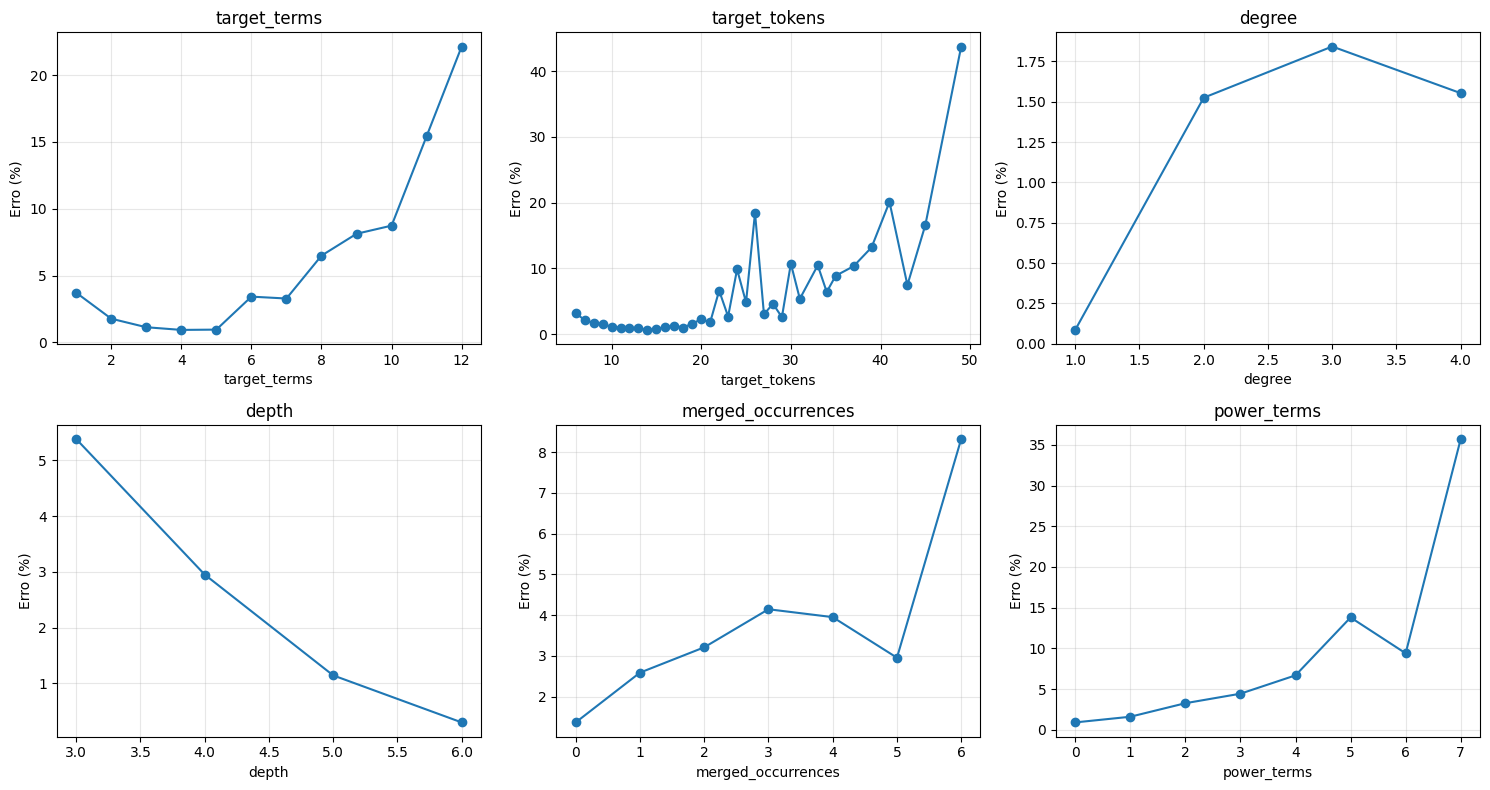

target_terms


,target_terms,examples,errors,error_pct,error_low_pct,error_high_pct
0,1,296,11,3.7162,2.0875,6.5308
1,2,20465,362,1.7689,1.5971,1.9587
2,3,154447,1744,1.1292,1.0777,1.1831
3,4,317199,2945,0.9284,0.8957,0.9624
4,5,194870,1852,0.9504,0.9083,0.9944
5,6,107957,3692,3.4199,3.3131,3.5300
6,7,18542,608,3.2790,3.0322,3.5452
7,8,23063,1497,6.4909,6.1801,6.8162
8,9,8614,700,8.1263,7.5678,8.7222
9,10,2438,213,8.7367,7.6797,9.9234


target_tokens


,target_tokens,examples,errors,error_pct,error_low_pct,error_high_pct
0,3,2,1,50.0000,9.4531,90.5469
1,4,12,0,0.0000,0.0000,24.2494
2,5,86,6,6.9767,3.2365,14.3961
3,6,374,12,3.2086,1.8448,5.5238
4,7,1049,22,2.0972,1.3890,3.1550
5,8,4706,80,1.7000,1.3681,2.1106
6,9,13701,213,1.5546,1.3606,1.7758
7,10,31851,347,1.0894,0.9812,1.2095
8,11,59335,585,0.9859,0.9095,1.0687
9,12,83735,734,0.8766,0.8157,0.9420


degree


,degree,examples,errors,error_pct,error_low_pct,error_high_pct
0,1,1168,1,0.0856,0.0151,0.4834
1,2,166778,2544,1.5254,1.4677,1.5853
2,3,354764,6538,1.8429,1.7992,1.8877
3,4,327755,5092,1.5536,1.5118,1.5965


... (2 outputs left out)

merged_occurrences


,merged_occurrences,examples,errors,error_pct,error_low_pct,error_high_pct
0,0,681388,9338,1.3704,1.3431,1.3983
1,1,119281,3090,2.5905,2.5019,2.6822
2,2,35217,1131,3.2115,3.0324,3.4008
3,3,8830,366,4.1450,3.7488,4.5810
4,4,4302,170,3.9517,3.4094,4.5761
5,5,744,22,2.9570,1.9607,4.4365
6,6,577,48,8.3189,6.3318,10.8573
7,7,50,5,10.0000,4.3476,21.3602
8,8,64,4,6.2500,2.4571,14.9975
9,9,8,0,0.0000,0.0000,32.4408


power_terms


,power_terms,examples,errors,error_pct,error_low_pct,error_high_pct
0,0,444528,3992,0.8980,0.8707,0.9262
1,1,260082,4145,1.5937,1.5463,1.6426
2,2,93339,3040,3.2569,3.1450,3.3728
3,3,33283,1473,4.4257,4.2099,4.6519
4,4,15300,1022,6.6797,6.2949,7.0863
5,5,2284,315,13.7916,12.4382,15.2666
6,6,1523,143,9.3894,8.0249,10.9581
7,7,126,45,35.7143,27.8844,44.3895


In [8]:
categories=data.groupby('error_category').agg(examples=('exact','size')).reset_index()
categories['% do teste']=100*categories.examples/len(data)
categories['% dos erros']=np.where(categories.error_category!='correct',100*categories.examples/(~data.exact).sum(),np.nan)
display(categories.sort_values('examples',ascending=False).round(4))
print('Erros que inventam um lag ausente na entrada:',int(((data.hallucinated_input_lags>0)&~data.exact).sum()))
print('Erros apenas na multiplicidade dos fatores:',int(data.multiplicity_only_error.sum()))
print('Erros corrigíveis apenas com ordenação e remoção de termos duplicados:',int((data.support_correct_after_sorting&~data.exact).sum()))
tables={field:grouped_errors(data,field) for field in
        ['target_terms','target_tokens','degree','depth','merged_occurrences','power_terms']}
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,(field,table) in zip(axes.flat,tables.items()):
    enough=table[table.examples>=100]
    ax.plot(enough[field],enough.error_pct,'o-')
    ax.set(title=field,xlabel=field,ylabel='Erro (%)');ax.grid(alpha=.3)
fig.tight_layout();plt.show()
for field,table in tables.items():
    print(field);display(table.round(4))


**O que esta célula faz:** Separa falhas de ordem/duplicação de diferenças reais no suporte e mostra taxas por vários tipos de complexidade. As tabelas incluem todos os grupos; os gráficos omitem grupos com menos de 100 casos.

In [9]:
from collections import Counter
substitutions=[]
for r in data[(~data.exact)&(~data.support_correct_after_sorting)&(data.error_category!='incomplete_syntax')].itertuples():
    truth=set(codec.decode(list(r.target_ids)[1:])['skeleton'])
    predicted=set(tuple(sorted(term)) for term in codec.decode(list(r.prediction_ids))['skeleton'])
    missing,extra=truth-predicted,predicted-truth
    if len(missing)==1 and len(extra)==1:
        old,new=Counter(next(iter(missing))),Counter(next(iter(extra)))
        removed,added=old-new,new-old
        if sum(removed.values())==1 and sum(added.values())==1:
            substitutions.append({'sample_index':r.sample_index,'removed_lag':next(iter(removed))[1],
                                  'added_lag':next(iter(added))[1],
                                  'added_was_in_input':codec.atom_token(*next(iter(added))) in r.prefix_ids})
substitutions=pd.DataFrame(substitutions)
print('Erros com exatamente um fator trocado em um termo:',len(substitutions))
if len(substitutions):
    print('Fator trocado por outro que já existia na entrada (%):',100*substitutions.added_was_in_input.mean())
    display(substitutions.groupby(['removed_lag','added_lag']).size().rename('casos').reset_index().sort_values('casos',ascending=False).head(12))


Erros com exatamente um fator trocado em um termo: 3427
Fator trocado por outro que já existia na entrada (%): 99.94163991829589


,removed_lag,added_lag,casos
107,10,9,209
83,8,7,125
118,11,9,117
119,11,10,111
95,9,8,103
129,12,9,101
47,5,4,92
106,10,8,82
117,11,8,79
131,12,11,71


**O que esta célula faz:** Decompõe os erros restantes para verificar se um único fator foi trocado e se o lag escolhido já fazia parte da entrada. Essa é uma descrição dos erros observados no teste completo.

## 6. Teste controlado: trocar a ordem dos filhos sem alterar a função

In [10]:
probe=commutative_probe(data,model,codec,config,count=10000,seed=SEED)
control_sample=data.sample(n=10000,random_state=SEED)
control_changes=0
with torch.inference_mode():
    for start in range(0,len(control_sample),config['batch_size']):
        block=control_sample.iloc[start:start+config['batch_size']]
        inputs=[diagnostic_example(row,codec) for row in block.to_dict('records')]
        tokens,_=model.generate(collate_canonical(inputs),config['max_decode_steps'])
        for row,prediction in zip(block.to_dict('records'),tokens.tolist()):
            prediction=prediction[:prediction.index(2)+1] if 2 in prediction else prediction
            control_changes+=int(prediction!=list(row['prediction_ids']))
transitions=pd.crosstab(probe.original_exact,probe.swapped_exact,dropna=False)
display(transitions)
probe_summary={
 'exemplos':len(probe),'previsão alterada':int(probe.changed_prediction.sum()),
 'erro original corrigido após troca':int((~probe.original_exact & probe.swapped_exact).sum()),
 'acerto original perdido após troca':int((probe.original_exact & ~probe.swapped_exact).sum()),
 'acerto original (%)':100*probe.original_exact.mean(),
 'acerto após troca (%)':100*probe.swapped_exact.mean(),
 'controle sem troca: previsões alteradas':control_changes,
}
display(pd.Series(probe_summary))
display(probe[probe.original_exact!=probe.swapped_exact].head(12))


swapped_exact,False,True
original_exact,,
False,101,67
True,47,9785


exemplos                                   10000.00
previsão alterada                            149.00
erro original corrigido após troca            67.00
acerto original perdido após troca            47.00
acerto original (%)                           98.32
acerto após troca (%)                         98.52
controle sem troca: previsões alteradas        0.00
dtype: float64

,sample_index,original_exact,swapped_exact,changed_prediction,original_formula,target_formula,original_prediction,swapped_prediction
175,3717183,False,True,True,((((x_0(t-10) + x_0(t-9)) + x_0(t-3)) * (x_0(t-4) + x_0(t-10))) + (x_0(t-3) * x_0(t-7))),s_0[t-3] * s_0[t-4] + s_0[t-3] * s_0[t-7] + s_0[t-3] * s_0[t-10] + s_0[t-4] * s_0[t-9] + s_0[t-4] * s_0[t-10] + s_0[t-9] * s_0[t-10] + s_0[t-10] * s_0[t-10],s_0[t-3] * s_0[t-4] + s_0[t-3] * s_0[t-7] + s_0[t-4] * s_0[t-9] + s_0[t-4] * s_0[t-10] + s_0[t-9] * s_0[t-10] + s_0[t-10] * s_0[t-10],s_0[t-3] * s_0[t-4] + s_0[t-3] * s_0[t-7] + s_0[t-3] * s_0[t-10] + s_0[t-4] * s_0[t-9] + s_0[t-4] * s_0[t-10] + s_0[t-9] * s_0[t-10] + s_0[t-10] * s_0[t-10]
239,1860720,False,True,True,(((((x_0(t-7) + x_0(t-7)) + x_0(t-1)) * x_0(t-2)) * x_0(t-9)) * (x_0(t-1) + x_0(t-7))),s_0[t-1] * s_0[t-1] * s_0[t-2] * s_0[t-9] + s_0[t-1] * s_0[t-2] * s_0[t-7] * s_0[t-9] + s_0[t-2] * s_0[t-7] * s_0[t-7] * s_0[t-9],s_0[t-1] * s_0[t-1] * s_0[t-2] * s_0[t-9] + s_0[t-1] * s_0[t-2] * s_0[t-7] * s_0[t-9] + s_0[t-1] * s_0[t-2] * s_0[t-7] * s_0[t-9] + s_0[t-2] * s_0[t-7] * s_0[t-7] * s_0[t-9],s_0[t-1] * s_0[t-1] * s_0[t-2] * s_0[t-9] + s_0[t-1] * s_0[t-2] * s_0[t-7] * s_0[t-9] + s_0[t-2] * s_0[t-7] * s_0[t-7] * s_0[t-9]
332,4012204,False,True,True,(((x_0(t-4) * x_0(t-5)) + x_0(t-7)) * ((x_0(t-6) + x_0(t-2)) + (x_0(t-8) + x_0(t-5)))),s_0[t-2] * s_0[t-7] + s_0[t-5] * s_0[t-7] + s_0[t-6] * s_0[t-7] + s_0[t-7] * s_0[t-8] + s_0[t-2] * s_0[t-4] * s_0[t-5] + s_0[t-4] * s_0[t-5] * s_0[t-5] + s_0[t-4] * s_0[t-5] * s_0[t-6] + s_0[t-4] * s_0[t-5] * s_0[t-8],s_0[t-2] * s_0[t-7] + s_0[t-5] * s_0[t-7] + s_0[t-7] * s_0[t-7] + s_0[t-7] * s_0[t-8] + s_0[t-2] * s_0[t-4] * s_0[t-5] + s_0[t-4] * s_0[t-5] * s_0[t-5] + s_0[t-4] * s_0[t-5] * s_0[t-6] + s_0[t-4] * s_0[t-5] * s_0[t-8],s_0[t-2] * s_0[t-7] + s_0[t-5] * s_0[t-7] + s_0[t-6] * s_0[t-7] + s_0[t-7] * s_0[t-8] + s_0[t-2] * s_0[t-4] * s_0[t-5] + s_0[t-4] * s_0[t-5] * s_0[t-5] + s_0[t-4] * s_0[t-5] * s_0[t-6] + s_0[t-4] * s_0[t-5] * s_0[t-8]
340,1113632,False,True,True,((x_0(t-6) * ((x_0(t-4) * x_0(t-6)) + x_0(t-12))) * ((x_0(t-1) + x_0(t-12)) + -0.463174)),s_0[t-6] * s_0[t-12] + s_0[t-1] * s_0[t-6] * s_0[t-12] + s_0[t-4] * s_0[t-6] * s_0[t-6] + s_0[t-6] * s_0[t-12] * s_0[t-12] + s_0[t-1] * s_0[t-4] * s_0[t-6] * s_0[t-6] + s_0[t-4] * s_0[t-6] * s_0[t-6] * s_0[t-12],s_0[t-6] * s_0[t-12] + s_0[t-1] * s_0[t-6] * s_0[t-12] + s_0[t-4] * s_0[t-6] * s_0[t-6] + s_0[t-6] * s_0[t-6] * s_0[t-12] + s_0[t-1] * s_0[t-4] * s_0[t-6] * s_0[t-6] + s_0[t-4] * s_0[t-6] * s_0[t-6] * s_0[t-12],s_0[t-6] * s_0[t-12] + s_0[t-1] * s_0[t-6] * s_0[t-12] + s_0[t-4] * s_0[t-6] * s_0[t-6] + s_0[t-6] * s_0[t-12] * s_0[t-12] + s_0[t-1] * s_0[t-4] * s_0[t-6] * s_0[t-6] + s_0[t-4] * s_0[t-6] * s_0[t-6] * s_0[t-12]
416,2206558,True,False,True,(((x_0(t-12) + x_0(t-7)) * x_0(t-2)) * (((-0.442021 * x_0(t-3)) + x_0(t-10)) + x_0(t-11))),s_0[t-2] * s_0[t-3] * s_0[t-7] + s_0[t-2] * s_0[t-3] * s_0[t-12] + s_0[t-2] * s_0[t-7] * s_0[t-10] + s_0[t-2] * s_0[t-7] * s_0[t-11] + s_0[t-2] * s_0[t-10] * s_0[t-12] + s_0[t-2] * s_0[t-11] * s_0[t-12],s_0[t-2] * s_0[t-3] * s_0[t-7] + s_0[t-2] * s_0[t-3] * s_0[t-12] + s_0[t-2] * s_0[t-7] * s_0[t-10] + s_0[t-2] * s_0[t-7] * s_0[t-11] + s_0[t-2] * s_0[t-10] * s_0[t-12] + s_0[t-2] * s_0[t-11] * s_0[t-12],s_0[t-2] * s_0[t-3] * s_0[t-7] + s_0[t-2] * s_0[t-3] * s_0[t-12] + s_0[t-2] * s_0[t-7] * s_0[t-10] + s_0[t-2] * s_0[t-7] * s_0[t-11] + s_0[t-2] * s_0[t-7] * s_0[t-12] + s_0[t-2] * s_0[t-10] * s_0[t-12]
419,1118982,True,False,True,((x_0(t-3) * (x_0(t-3) + x_0(t-1))) + ((x_0(t-11) + x_0(t-7)) * x_0(t-6))),s_0[t-1] * s_0[t-3] + s_0[t-3] * s_0[t-3] + s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-11],s_0[t-1] * s_0[t-3] + s_0[t-3] * s_0[t-3] + s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-11],s_0[t-1] * s_0[t-3] + s_0[t-3] * s_0[t-3] + s_0[t-3] * s_0[t-6] + s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-11]
488,3351002,True,False,True,((x_0(t-1) + (x_0(t-1) + (x_0(t-3) * x_0(t-8)))) * ((x_0(t-6) + x_0(t-3)) + x_0(t-3))),s_0

**O que esta célula faz:** Troca sistematicamente esquerda e direita em cada soma e multiplicação para 10.000 casos escolhidos independentemente do acerto. A identidade matemática é preservada, o que permite verificar sensibilidade à organização da entrada.

## 7. Teste controlado nos 110 casos com quatro operações

A taxa de erro de 20% em quatro operações contraria uma interpretação simples de que árvores menores sempre seriam mais fáceis. O treino contém apenas 699 dessas árvores, contra 3.452.052 com seis operações. Para investigar a sensibilidade à representação, avaliamos todos os 110 casos de teste com quatro operações usando também a entrada equivalente $e\,(0{,}5+0{,}5)$. Essa identidade preserva exatamente a função, seus coeficientes e seu skeleton, acrescentando duas operações à entrada. O modelo recebe 13 nós, dentro do comprimento utilizado no treinamento. A intervenção modifica conjuntamente o tamanho, a forma e a presença de constantes; portanto, seu resultado informa sobre a representação da entrada, sem isolar qual dessas mudanças é responsável.

In [11]:
small=data[data.operator_count==4].sort_values('sample_index').copy()
small_inputs=[diagnostic_example(row,codec) for row in small.to_dict('records')]
padded=[]
for example in small_inputs:
    augmented={**example,
        'prefix_ids':[2]+example['prefix_ids']+[1,3,3],
        'prefix_values':[0.]+example['prefix_values']+[0.,0.5,0.5]}
    augmented=swap_children(swap_children(augmented))
    assert len(augmented['prefix_ids'])==13
    assert structural_features(augmented)['operator_count']==6
    assert augmented['target']==example['target']
    padded.append(augmented)
assert 0.5+0.5==1.0
with torch.inference_mode():
    padded_tokens,_=model.generate(collate_canonical(padded),config['max_decode_steps'])
    original_tokens,_=model.generate(collate_canonical(small_inputs),config['max_decode_steps'])
padding_results=[classify_prediction(e,t,codec) for e,t in zip(padded,padded_tokens.tolist())]
small_control=[classify_prediction(e,t,codec)['exact'] for e,t in zip(small_inputs,original_tokens.tolist())]
assert np.array_equal(small_control,small.exact.to_numpy())
padding_correct=np.array([r['exact'] for r in padding_results])
padding_summary={'examples':len(small),'original_correct':int(small.exact.sum()),
    'padded_correct':int(padding_correct.sum()),
    'rescued':int((~small.exact.to_numpy()&padding_correct).sum()),
    'broken':int((small.exact.to_numpy()&~padding_correct).sum())}
display(pd.Series(padding_summary))
padding_table=case_table(small)
padding_table['Saída após multiplicar por (0,5 + 0,5)']=[short_formula(r['predicted_formula']) for r in padding_results]
display(padding_table.loc[~small.exact].style.set_properties(**{'white-space':'normal','max-width':'400px'}))


examples            110
original_correct     88
padded_correct      110
rescued              22
broken                0
dtype: int64

,sample_index,Operações,Termos no alvo,Grau,Fórmula da AST,Skeleton correto,Saída prevista,Tipo de erro,Termos ausentes,Termos adicionais,"Saída após multiplicar por (0,5 + 0,5)"
9994,49894,4,3,2,((x_9 + (x_3 * x_5)) + (x_11 * x_10)),x_9 + x_3 * x_5 + x_10 * x_11,x_9 + x_3 * x_5 + x_10 * x_11 + x_10 * x_11,ordering_or_duplicate_only,,,x_9 + x_3 * x_5 + x_10 * x_11
36696,186727,4,2,3,(x_3 * ((x_3 * (-0.323977 * x_8)) + x_5)),x_3 * x_5 + x_3 * x_3 * x_8,x_3 * x_5 + x_3 * x_3 * x_3 * x_8,missing_and_extra_terms,x_3 * x_3 * x_8,x_3 * x_3 * x_3 * x_8,x_3 * x_5 + x_3 * x_3 * x_8
66789,344966,4,2,4,(x_1 * (x_6 + ((x_3 * x_7) * x_1))),x_1 * x_6 + x_1 * x_1 * x_3 * x_7,x_1 * x_6 + x_1 * x_1 * x_1 * x_3 * x_7,missing_and_extra_terms,x_1 * x_1 * x_3 * x_7,x_1 * x_1 * x_1 * x_3 * x_7,x_1 * x_6 + x_1 * x_1 * x_3 * x_7
96555,504303,4,4,2,((x_9 + (x_2 + x_6)) + (x_2 * x_1)),x_2 + x_6 + x_9 + x_1 * x_2,x_2 + x_6 + x_9 + x_1 * x_2 * x_2,missing_and_extra_terms,x_1 * x_2,x_1 * x_2 * x_2,x_2 + x_6 + x_9 + x_1 * x_2
127092,669389,4,3,3,(x_10 * (((x_2 * x_6) + x_8) + x_11)),x_8 * x_10 + x_10 * x_11 + x_2 * x_6 * x_10,x_8 * x_10 + x_10 * x_11 + x_2 * x_6 * x_10 + x_2 * x_6 * x_10,ordering_or_duplicate_only,,,x_8 * x_10 + x_10 * x_11 + x_2 * x_6 * x_10
172500,916988,4,4,3,((x_7 + x_1) * ((x_2 + -0.351685) * x_12)),x_1 * x_12 + x_7 * x_12 + x_1 * x_2 * x_12 + x_2 * x_7 * x_12,x_1 * x_12 + x_7 * x_12 + x_1 * x_2 * x_12 + x_1 * x_12 * x_12 + x_2 * x_7 * x_12 + x_7 * x_12 * x_12,extra_terms_only,,x_1 * x_12 * x_12 + x_7 * x_12 * x_12,x_1 * x_12 + x_7 * x_12 + x_1 * x_2 * x_12 + x_2 * x_7 * x_12
175073,931072,4,3,3,(x_2 * (((x_8 + x_5) * x_5) + x_1)),x_1 * x_2 + x_2 * x_5 * x_5 + x_2 * x_5 * x_8,x_1 * x_2 + x_2 * x_2 * x_5 * x_5 + x_2 * x_2 * x_5 * x_8,missing_and_extra_terms,x_2 * x_5 * x_5 + x_2 * x_5 * x_8,x_2 * x_2 * x_5 * x_5 + x_2 * x_2 * x_5 * x_8,x_1 * x_2 + x_2 * x_5 * x_5 + x_2 * x_5 * x_8
178208,948004,4,2,3,(x_7 * ((x_12 + x_12) * (x_6 + x_10))),x_6 * x_7 * x_12 + x_7 * x_10 * x_12,x_6 * x_7 * x_12 * x_12 + x_7 * x_10 * x_12 * x_12,missing_and_extra_terms,x_6 * x_7 * x_12 + x_7 * x_10 * x_12,x_6 * x_7 * x_12 * x_12 + x_7 * x_10 * x_12 * x_12,x_6 * x_7 * x_12 + x_7 * x_10 * x_12
186074,991633,4,4,2,(x_6 * (-0.537013 + ((x_11 + x_9) + x_8))),x_6 + x_6 * x_8 + x_6 * x_9 + x_6 * x_11,x_6 + x_6 * x_6 + x_6 * x_8 + x_6 * x_9 + x_6 * x_11,extra_terms_only,,x_6 * x_6,x_6 + x_6 * x_8 + x_6 * x_9 + x_6 * x_11
202102,1080116,4,2,3,(0.559453 * (x_4 * ((x_10 + x_6) * x_6))),x_4 * x_6 * x_6 + x_4 * x_6 * x_10,x_4 * x_6 * x_6 * x_6 + x_4 * x_6 * x_6 * x_10,missing_and_extra_terms,x_4 * x_6 * x_6 + x_4 * x_6 * x_10,x_4 * x_6 * x_6 * x_6 + x_4 * x_6 * x_6 * x_10,x_4 * x_6 * x_6 + x_4 * x_6 * x_10


**O que esta célula faz:** Compara a mesma função antes e depois de uma mudança algébrica neutra na entrada. Inclui todos os casos com quatro operações, confere a inferência original e mostra cada erro corrigido ou preservado.

## 8. Distribuição do corpus e limites da interpretação

In [12]:
corpus=json.loads((RUN/'status.json').read_text(encoding='utf8'))['corpus']
distribution=[]
for split,counts in corpus['operator_counts_by_split'].items():
    for operations,count in counts.items():
        distribution.append({'partição':split,'operações':int(operations),'exemplos':count,
                             'percentual':100*count/corpus['rows_by_split'][split]})
display(pd.DataFrame(distribution).sort_values(['operações','partição']).round(4))


,partição,operações,exemplos,percentual
3,train,3,6,0.0002
7,validation,3,1,0.0002
10,test,4,110,0.0129
2,train,4,699,0.0200
6,validation,4,50,0.0118
9,test,5,9855,1.1588
1,train,5,47275,1.3507
5,validation,5,4969,1.1686
8,test,6,840500,98.8283
0,train,6,3452052,98.6292


**O que esta célula faz:** Mostra o suporte efetivamente presente no treino e no teste. O experimento cobre principalmente seis operações; resultados em classes quase ausentes exigem novas amostras específicas.

Os padrões devem ser interpretados no domínio do experimento: uma série, lags 1–12, soma e multiplicação, até seis operações e grau máximo quatro. A análise trata de um checkpoint treinado uma vez. A inspeção do teste serve ao diagnóstico; futuras mudanças sugeridas por estes resultados devem ser confirmadas em novo teste. Um erro de saída pode envolver representação da entrada, geração sequencial e ordenação; as tabelas não isolam sozinhas qual componente interno da rede é responsável.

### Interpretação dos resultados

- **A dificuldade depende da estrutura da conta.** Produtos entre duas somas têm erro de 4,75%, contra 0,71% nos demais casos. A diferença permanece positiva quando operações, quantidade de termos e grau são mantidos iguais. Agrupar ocorrências do mesmo monômio e preservar fatores repetidos também concentram erros. Uma saída longa sinaliza risco, mas sua associação diminui e muda de sinal na comparação estratificada: parte do efeito aparente está relacionada à composição das expressões.
- **Há falhas de organização da saída.** Em 3.069 dos 14.175 erros, ordenar os fatores/termos e remover termos duplicados basta para recuperar o skeleton. A multiplicidade dentro de cada termo deve ser preservada, pois $x^2$ e $x$ são dependências diferentes. Essa recuperação levaria o acerto de 98,33% para 98,69% neste teste.
- **Há confusões entre lags que já aparecem na entrada.** Em 3.427 erros, um único fator é substituído em um único termo; em 3.425 deles, o fator escolhido já estava na AST. Isso sugere dificuldade para preservar as participações de cada lag durante a transformação.
- **A organização da entrada afeta o resultado.** Trocar os operandos em 10.000 casos altera 149 previsões, corrige 67 erros e introduz 47 novos. Repetir a inferência sem trocar os operandos altera zero previsões. Nos 110 casos com quatro operações, multiplicar a entrada por $(0{,}5+0{,}5)$ aumenta o acerto de 88 para 110 casos. A função e o skeleton permanecem iguais. O resultado é compatível com sensibilidade à distribuição das formas de ASTs vista no treino; demonstrar que o desbalanceamento é a causa exige comparar novos treinamentos.

As ações sugeridas por este diagnóstico são: garantir amostras suficientes por número de operações; incluir representações equivalentes de cada função durante o treino, respeitando a separação entre skeletons dos conjuntos; aumentar a presença de distributivas e de termos repetidos; e impor ordenação e ausência de termos duplicados durante o decoding. Estas são hipóteses para os próximos experimentos. O checkpoint avaliado permanece inalterado e o treinamento permanece pausado.

## 9. Registro completo do experimento executado

In [13]:
record={
 'research_question':'Quais estruturas de AST e de skeleton concentram erros do checkpoint final?',
 'hypotheses':SELECTED_HYPOTHESES,
 'configuration':{'model_config':config,'analysis_threads':4,'partition':'10% descoberta / 90% confirmação por hash do skeleton',
                  'discovery_selection_rows':len(selection_slice),'selection_source_shards':24,
                  'commutative_probe_examples':10000,'probe_seed':SEED},
 'provenance':{'checkpoint':str(CHECKPOINT),'epoch':checkpoint_epoch,
               'checkpoint_sha256':manifest['checkpoint_sha256'],'corpus':corpus,
               'analysis_code_sha256':manifest['analysis_code_sha256'],
               'python':platform.python_version(),'torch':torch.__version__},
 'metrics':global_metrics,
 'confirmation':hypothesis_confirmation.to_dict('records'),
 'full_test':hypothesis_full.to_dict('records'),
 'stratified':stratified.to_dict('records'),
 'commutative_probe':probe_summary,
 'neutral_padding_probe':padding_summary,
 'scientific_summary':f"Teste completo: {100*data.exact.mean():.4f}% de skeletons exatos; "
     f"{int((data.support_correct_after_sorting&~data.exact).sum())} falhas envolvem apenas ordenação/duplicação; "
     'associações confirmadas e comparação estratificada estão nas tabelas acima. Nenhum peso foi atualizado.',
 'reproduction':[
     '.venv/Scripts/python.exe scripts/analyze_canonical_errors.py',
     '.venv/Scripts/python.exe scripts/execute_notebook_background.py --notebook experiments/canonicalization/error_analysis/5_skeleton_errors.ipynb --run-dir outputs/canonicalization/error_analysis_notebook_20261031'],
 'artifacts':{'per_example_parquet':str(AUDIT),'checkpoint_read_only':str(CHECKPOINT)},
}
from pprint import pprint
pprint(record,sort_dicts=False)


{'research_question': 'Quais estruturas de AST e de skeleton concentram erros '
                      'do checkpoint final?',
 'hypotheses': ['at_least_25_output_tokens',
                'product_of_two_sums',
                'at_least_two_merged_occurrences',
                'power_in_target',
                'degree_four',
                'deep_tree'],
 'configuration': {'model_config': {'experiment': 'canonical_ast_5m_unique_eval_20261030',
                                    'ast_count': 5000000,
                                    'shard_size': 20000,
                                    'generation_workers': 4,
                                    'generator': {'minimum_operators': 1,
                                                  'maximum_operators': 6,
                                                  'num_series': 1,
                                                  'minimum_lag': 1,
                                                  'maximum_lag': 12,
                        

**O que esta célula faz:** Registra configuração, proveniência, seeds, hipóteses, métricas, limitações e os comandos de reprodução no próprio notebook.